# Smoothing

Can we make a noisy pattern easier to see without accidentally reading the future? Compare causal trailing averages on the same observations.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp smoothing

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `smoothing`

### Imports and configuration

In [3]:
#| export smoothing
import pandas as pd

### simple_moving_average

In [4]:
#| export smoothing
def simple_moving_average(df, window_length=30, min_periods=1):
    df = pd.DataFrame(df)
    ma = df.iloc[:, 0].rolling(window_length, min_periods=min_periods).mean()
    ma.rename(f"{df.columns[0]}_MA{window_length}", inplace=True)
    return pd.concat([df, ma], axis=1)

### exponential_moving_average — Return a pandas exponentially weighted mean with an explicit alpha.

In [5]:
#| export smoothing
def exponential_moving_average(df, exponential_alpha=None, statistic="mean"):
    """Return a pandas exponentially weighted mean with an explicit alpha."""
    if statistic != "mean":
        raise ValueError("Only statistic='mean' is supported; pandas EWM does not provide a median")
    if exponential_alpha is None:
        raise ValueError("Supply exponential_alpha in (0, 1]")
    return df.copy().ewm(alpha=exponential_alpha).mean()

## Change the smoothing scale

/var/folders/0y/vp5pzdmn1zv6fq6d862gqm200000gn/T/ipykernel_92288/3738879989.py:5: Pandas4Warning: The inplace keyword in Series.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ma.rename(f"{df.columns[0]}_MA{window_length}", inplace=True)


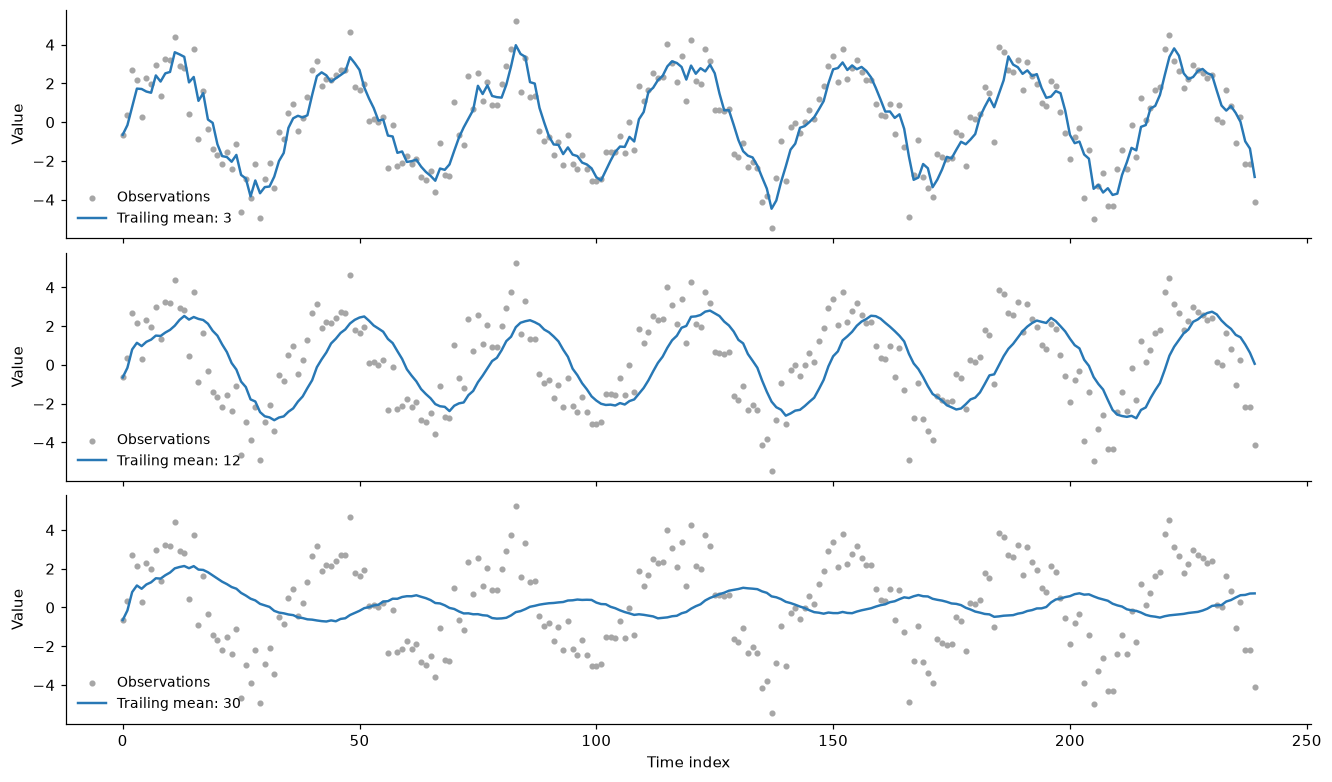

In [6]:
from timegym import Scenario
case = Scenario('seasonal', context_length=240, horizon=24,
                parameters={'amplitude': 3., 'period': 36., 'sigma': 1.}).generate(seed=4)
context = case.task.context
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, layout='constrained')
for ax, window in zip(axes, [3, 12, 30]):
    smooth = simple_moving_average(context, window_length=window)
    ax.scatter(context.index, context['y'], s=9, color='.65', label='Observations')
    ax.plot(smooth.index, smooth.iloc[:, -1], color='#2878b5', lw=1.6, label=f'Trailing mean: {window}')
    ax.set_ylabel('Value'); ax.legend(fontsize=9)
axes[-1].set_xlabel('Time index')
plt.show()
pd.testing.assert_frame_equal(simple_moving_average(context.iloc[:100], window_length=12),
                               simple_moving_average(context, window_length=12).iloc[:100])

Longer windows remove more noise and lag the changing signal. These curves are transformations of observed history, not future forecasts. For a feature predicting the current row, shift the trailing statistic so that row is not included.

## Exponential weighting

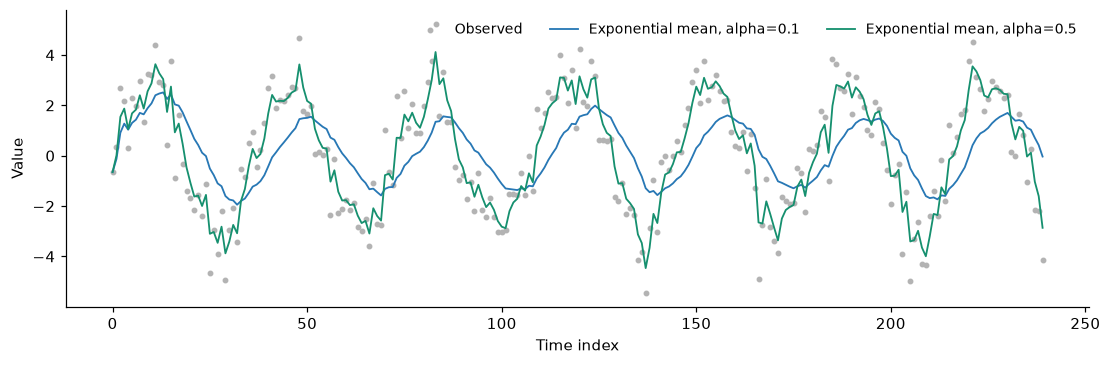

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.scatter(context.index, context['y'], s=8, color='.7', label='Observed')
for alpha, color in [(0.1, '#2878b5'), (0.5, '#16906f')]:
    smoothed = exponential_moving_average(context, exponential_alpha=alpha)
    ax.plot(smoothed.index, smoothed['y'], color=color, lw=1.2, label=f'Exponential mean, alpha={alpha}')
ax.set(xlabel='Time index', ylabel='Value')
ax.legend(ncol=3, fontsize=9)
plt.show()

The package implements means with explicit parameters. The Kalman and Gaussian-process ideas in the historical notebook remain unimplemented.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.